# Assignment 3A — Explore and Plan
## Alzheimer's disease: a patient-level exploratory analysis

This notebook answers all Part A deliverables: planned examinations, data audit, a variable dictionary, selected exploratory analyses, three research questions with plans and preliminary answers, and a data-quality note. The questions are distinct and use only available variables. Results describe this dataset; they do not establish causation, future disease risk, or clinical usefulness.

**Run in Colab:** select **Runtime → Run all**, then upload `alzheimers_disease_data.csv` when prompted. A local CSV beside the notebook is also supported. No GPU is needed. `data.h5` is not required for the analyses.

**Sources and scope.** The supplied assignment paper defines the required analyses; the supplied data dictionary defines coding and stated ranges. The CSV supplies all results. The [linked Google Sheet](https://docs.google.com/spreadsheets/d/1zqJ3PM_RNpsgqp_PvD9jfph84sC0nhf-Gh2tHJ51nTs/edit#gid=0), inspected on 24 November 2026, is a class submission register with names and notebook links, not another set of analytical questions. It was not edited, and other students' notebooks were not used as evidence. The assignment permits AI implementation and debugging; the submitting student remains responsible for reviewing the analysis and decisions.


## 1. Plan before implementation

All **five examination bullets** in assignment section 1 are covered below.

| Examination | Planned approach | Location |
|---|---|---|
| Dimensions, names, types, representative rows | Shape, schema, beginning/middle/end rows | 2 |
| Unit of observation and variable roles | Check identifier uniqueness; separate measurements, groups, and possible outcomes | 2–3 |
| Semantic variable types | Classify all 35 fields independently of storage dtype | 3 |
| Unique values, category counts, ranges and summaries | Counts/proportions for coded categories; descriptive statistics for measurements | 4–5 |
| Missingness, duplicates, constants, suspicious values, precision and coding | Explicit checks against dictionary and cross-field flags | 4 |

**Additional checks:** duplicates excluding the identifier; identifier sequence versus stated bounds; finite numeric values; blank strings; systolic/diastolic ordering; LDL versus total cholesterol; fractional assessment scores; outcome proportion by identifier order; source fingerprint; and separate inspection of the optional HDF5 file.

**Analysis decisions made before interpretation:** preserve original values; flag suspect records rather than silently correcting or deleting them; exclude identifiers and the constant doctor placeholder from substantive relationships; treat ethnicity and gender as nominal, education as ordinal, and binary indicators as categorical. Use a small number of plots with meaningful scales. Use Spearman correlation only for selected measurements. Age strata are 60–69, 70–79 and 80–90 years; they are descriptive bands, not clinical thresholds. Do not fit a predictive model for this exploratory assignment.


In [1]:
from pathlib import Path
import hashlib, sys, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 40)
pd.set_option('display.precision', 3)
print('Python:', sys.version.split()[0])
for package in ['pandas', 'numpy', 'matplotlib']:
    print(package, importlib.metadata.version(package))
DATA_PATH = Path('alzheimers_disease_data.csv')
if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Place alzheimers_disease_data.csv beside this notebook, then run again.')
    uploaded = files.upload()
    if DATA_PATH.name not in uploaded:
        raise FileNotFoundError('Upload the file named alzheimers_disease_data.csv.')
df = pd.read_csv(DATA_PATH)
print('CSV SHA-256:', hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())


Python: 3.14.5
pandas 3.1.1
numpy 2.5.5
matplotlib 3.11.2
CSV SHA-256: 66f51dbb5f00a4bf6ed1f631e72ec15e4a8e97dc223c10f78c1febec95a2be07


## 2. What does a row represent?

Each row appears to represent one patient record: `PatientID` is unique in this file. There are no dates, follow-up visits, recruitment details or site identifiers, so this is treated as a cross-sectional table. Unique IDs alone do not prove that the records are independent or authentic clinical observations.

`PatientID` is an identifier; `Diagnosis` is a recorded binary outcome for question 1. `MMSE` and `ADL` can instead be outcomes for questions 3 and 2. Demographics and medical-history indicators provide groups; lifestyle, clinical and assessment fields provide measurements. `DoctorInCharge` is a constant confidentiality placeholder and cannot support comparisons between doctors.


In [2]:
print(f'{len(df):,} rows × {df.shape[1]} columns')
display(pd.DataFrame({'column': df.columns, 'storage_dtype': df.dtypes.astype(str).values}))
display(df.iloc[[0, len(df)//2, len(df)-1]])
print('Unique patient identifiers:', df.PatientID.nunique())


2,149 rows × 35 columns


,column,storage_dtype
0,PatientID,int64
1,Age,int64
2,Gender,int64
3,Ethnicity,int64
4,EducationLevel,int64
5,BMI,float64
6,Smoking,int64
7,AlcoholConsumption,float64
8,PhysicalActivity,float64
9,DietQuality,float64


,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryAlzheimers,CardiovascularDisease,Diabetes,Depression,HeadInjury,Hypertension,SystolicBP,DiastolicBP,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,MMSE,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.928,0,13.297,6.327,1.347,9.026,0,0,1,1,0,0,142,72,242.367,56.151,33.683,162.189,21.464,6.519,0,0,1.726,0,0,0,1,0,0,XXXConfid
1074,5825,60,0,0,1,16.167,0,8.867,7.993,1.635,5.371,0,0,0,0,0,0,154,98,233.529,112.746,47.485,100.896,1.683,6.868,0,0,4.719,0,0,0,0,0,0,XXXConfid
2148,6899,72,0,0,2,33.290,0,7.891,6.571,7.941,9.879,0,0,0,0,0,0,166,78,283.397,92.200,81.920,217.397,11.115,6.308,0,1,8.328,0,1,0,0,1,0,XXXConfid


Unique patient identifiers: 2149


## 3. Short data dictionary and coding uncertainties

The following table covers every supplied variable, including those used in the research questions. Numeric storage does not determine semantic type. Gender uses the source's two recorded labels; the coding does not establish how sex or gender was collected. Ethnicity labels are reproduced from the dictionary. Education has an order but the distances between categories are not numerical measurements. There are no date/time variables.

Assessment instruments, collection methods and score precision are insufficiently documented. MMSE, ADL and FunctionalAssessment are retained as supplied numerical scores, without inventing severity cutoffs. DietQuality and SleepQuality are numerical scores with undocumented construction. BMI is conventionally kg/m², but the supplied dictionary does not explicitly state its unit. Alcohol “units” are not defined by beverage amount or country.


In [3]:
category_maps = {
    'Gender': {0:'Male',1:'Female'},
    'Ethnicity': {0:'Caucasian',1:'African American',2:'Asian',3:'Other'},
    'EducationLevel': {0:'None',1:'High School',2:"Bachelor's",3:'Higher'},
}
binary = ['Smoking','FamilyHistoryAlzheimers','CardiovascularDisease','Diabetes',
          'Depression','HeadInjury','Hypertension','MemoryComplaints','BehavioralProblems',
          'Confusion','Disorientation','PersonalityChanges','DifficultyCompletingTasks',
          'Forgetfulness','Diagnosis']
for col in binary:
    category_maps[col] = {0:'No',1:'Yes'}
# Bounds and units come from the supplied dictionary, not estimated thresholds.
spec = {
    'Age':(60,90,'years'), 'BMI':(15,40,'unit unspecified; conventionally kg/m²'),
    'AlcoholConsumption':(0,20,'units/week; unit definition unspecified'),
    'PhysicalActivity':(0,10,'hours/week'), 'DietQuality':(0,10,'score'),
    'SleepQuality':(4,10,'score'), 'SystolicBP':(90,180,'mmHg'),
    'DiastolicBP':(60,120,'mmHg'), 'CholesterolTotal':(150,300,'mg/dL'),
    'CholesterolLDL':(50,200,'mg/dL'), 'CholesterolHDL':(20,100,'mg/dL'),
    'CholesterolTriglycerides':(50,400,'mg/dL'), 'MMSE':(0,30,'score; lower = more impairment'),
    'FunctionalAssessment':(0,10,'score; lower = more impairment'),
    'ADL':(0,10,'score; lower = more impairment')}
expected = set(spec) | set(category_maps) | {'PatientID','DoctorInCharge'}
assert set(df.columns) == expected, 'Unexpected schema: check the uploaded CSV.'
dictionary=[]
for col in df.columns:
    if col == 'PatientID':
        kind, meaning = 'identifier', 'Stated range 4751–6900; not a predictor'
    elif col == 'DoctorInCharge':
        kind, meaning = 'nominal / placeholder', 'XXXConfid; no doctor identity available'
    elif col in category_maps:
        kind = 'ordinal categorical' if col == 'EducationLevel' else ('binary categorical' if len(category_maps[col]) == 2 else 'nominal categorical')
        meaning = '; '.join(f'{k} = {v}' for k,v in category_maps[col].items())
    else:
        lo,hi,unit = spec[col]
        kind,meaning = 'numerical', f'{lo}–{hi}; {unit}'
    dictionary.append([col,kind,meaning])
dictionary = pd.DataFrame(dictionary, columns=['Variable','Semantic type','Meaning / coding'])
display(dictionary)


,Variable,Semantic type,Meaning / coding
0,PatientID,identifier,Stated range 4751–6900; not a predictor
1,Age,numerical,60–90; years
2,Gender,binary categorical,0 = Male; 1 = Female
3,Ethnicity,nominal categorical,0 = Caucasian; 1 = African American; 2 = Asian...
4,EducationLevel,ordinal categorical,0 = None; 1 = High School; 2 = Bachelor's; 3 =...
5,BMI,numerical,15–40; unit unspecified; conventionally kg/m²
6,Smoking,binary categorical,0 = No; 1 = Yes
7,AlcoholConsumption,numerical,0–20; units/week; unit definition unspecified
8,PhysicalActivity,numerical,0–10; hours/week
9,DietQuality,numerical,0–10; score


## 4. Data audit

The checks below report findings without changing the input. Range compliance is not proof of validity. Cross-field inconsistencies require source clarification; they are not a reason to manufacture corrected values. Frequency tables include all declared levels, including levels with zero records.


In [4]:
audit = pd.DataFrame({'missing':df.isna().sum(), 'unique':df.nunique(dropna=False)})
audit['blank_strings'] = [df[c].map(lambda x: isinstance(x,str) and not x.strip()).sum() for c in df]
display(audit)
print('Exact duplicate rows:', df.duplicated().sum())
print('Duplicate rows excluding PatientID:', df.drop(columns='PatientID').duplicated().sum())
print('Duplicate IDs:', df.PatientID.duplicated().sum())
print('Constant columns:', df.columns[df.nunique(dropna=False).eq(1)].tolist())
print('Observed ID range:', df.PatientID.min(), df.PatientID.max())
print('IDs absent from stated 4751–6900 range:', sorted(set(range(4751,6901))-set(df.PatientID)))
print('Nonfinite numeric cells:', (~np.isfinite(df.select_dtypes('number')) & df.select_dtypes('number').notna()).sum().sum())

validation=[]
for c,(lo,hi,unit) in spec.items():
    validation.append([c, int((df[c].notna() & ~df[c].between(lo,hi)).sum())])
for c,mapping in category_maps.items():
    validation.append([c, int((df[c].notna() & ~df[c].isin(mapping)).sum())])
validation.append(['PatientID', int((~df.PatientID.between(4751,6900) | df.PatientID.mod(1).ne(0)).sum())])
validation.append(['DoctorInCharge', int(df.DoctorInCharge.ne('XXXConfid').sum())])
display(pd.DataFrame(validation, columns=['Variable','Invalid range / code count']))
quality_flags = {
    'SystolicBP <= DiastolicBP': int((df.SystolicBP <= df.DiastolicBP).sum()),
    'CholesterolLDL > CholesterolTotal': int((df.CholesterolLDL > df.CholesterolTotal).sum()),
    'Fractional MMSE scores': int((~np.isclose(df.MMSE, df.MMSE.round(), atol=1e-8, rtol=0)).sum())}
display(pd.Series(quality_flags, name='Rows flagged').to_frame())
raw_text = pd.read_csv(DATA_PATH, dtype=str)
precision = {c:raw_text[c].str.extract(r'\.(\d+)',expand=False).str.len().max() for c in spec}
display(pd.Series(precision,name='Maximum decimal places in original CSV').to_frame())
print('Flags do not trigger automatic removal or rounding.')


,missing,unique,blank_strings
PatientID,0,2149,0
Age,0,31,0
Gender,0,2,0
Ethnicity,0,4,0
EducationLevel,0,4,0
BMI,0,2149,0
Smoking,0,2,0
AlcoholConsumption,0,2149,0
PhysicalActivity,0,2149,0
DietQuality,0,2149,0


Exact duplicate rows: 0
Duplicate rows excluding PatientID: 0
Duplicate IDs: 0
Constant columns: ['DoctorInCharge']
Observed ID range: 4751 6899
IDs absent from stated 4751–6900 range: [6900]
Nonfinite numeric cells: 0


,Variable,Invalid range / code count
0,Age,0
1,BMI,0
2,AlcoholConsumption,0
3,PhysicalActivity,0
4,DietQuality,0
5,SleepQuality,0
6,SystolicBP,0
7,DiastolicBP,0
8,CholesterolTotal,0
9,CholesterolLDL,0


,Rows flagged
SystolicBP <= DiastolicBP,186
CholesterolLDL > CholesterolTotal,114
Fractional MMSE scores,2149


,Maximum decimal places in original CSV
Age,NaN
BMI,15.0
AlcoholConsumption,19.0
PhysicalActivity,19.0
DietQuality,18.0
SleepQuality,16.0
SystolicBP,NaN
DiastolicBP,NaN
CholesterolTotal,14.0
CholesterolLDL,15.0


Flags do not trigger automatic removal or rounding.


In [5]:
category_tables=[]
for c,mapping in category_maps.items():
    counts=df[c].value_counts(dropna=False).reindex(mapping,fill_value=0)
    for value,n in counts.items():
        category_tables.append([c,value,mapping[value],n,100*n/len(df)])
category_counts=pd.DataFrame(category_tables,columns=['Variable','Code','Label','Count','Percent'])
display(category_counts)
display(df[list(spec)].describe().T.rename(columns={'25%':'Q1','50%':'Median','75%':'Q3'}))


,Variable,Code,Label,Count,Percent
0,Gender,0,Male,1061,49.372
1,Gender,1,Female,1088,50.628
2,Ethnicity,0,Caucasian,1278,59.470
3,Ethnicity,1,African American,454,21.126
4,Ethnicity,2,Asian,206,9.586
5,Ethnicity,3,Other,211,9.819
6,EducationLevel,0,None,446,20.754
7,EducationLevel,1,High School,854,39.739
8,EducationLevel,2,Bachelor's,636,29.595
9,EducationLevel,3,Higher,213,9.912


,count,mean,std,min,Q1,Median,Q3,max
Age,2149.0,74.909,8.990,6.000e+01,67.000,75.000,83.000,90.000
BMI,2149.0,27.656,7.217,1.501e+01,21.611,27.824,33.870,39.993
AlcoholConsumption,2149.0,10.039,5.758,2.003e-03,5.140,9.934,15.158,19.989
PhysicalActivity,2149.0,4.920,2.857,3.616e-03,2.571,4.766,7.428,9.987
DietQuality,2149.0,4.993,2.909,9.385e-03,2.458,5.076,7.559,9.998
SleepQuality,2149.0,7.051,1.764,4.003e+00,5.483,7.116,8.563,10.000
SystolicBP,2149.0,134.265,25.949,9.000e+01,112.000,134.000,157.000,179.000
DiastolicBP,2149.0,89.848,17.592,6.000e+01,74.000,91.000,105.000,119.000
CholesterolTotal,2149.0,225.198,42.542,1.501e+02,190.253,225.086,262.032,299.993
CholesterolLDL,2149.0,124.336,43.367,5.023e+01,87.196,123.343,161.734,199.966


## 5. Selected exploratory patterns

Figure 1 checks the distributions of age, cognitive score, daily-function score and activity. Figure 2 shows diagnosis balance. Later figures answer the three questions directly. Means, medians, standard deviations and quartiles appear in the tables, avoiding repeated plots of every variable.


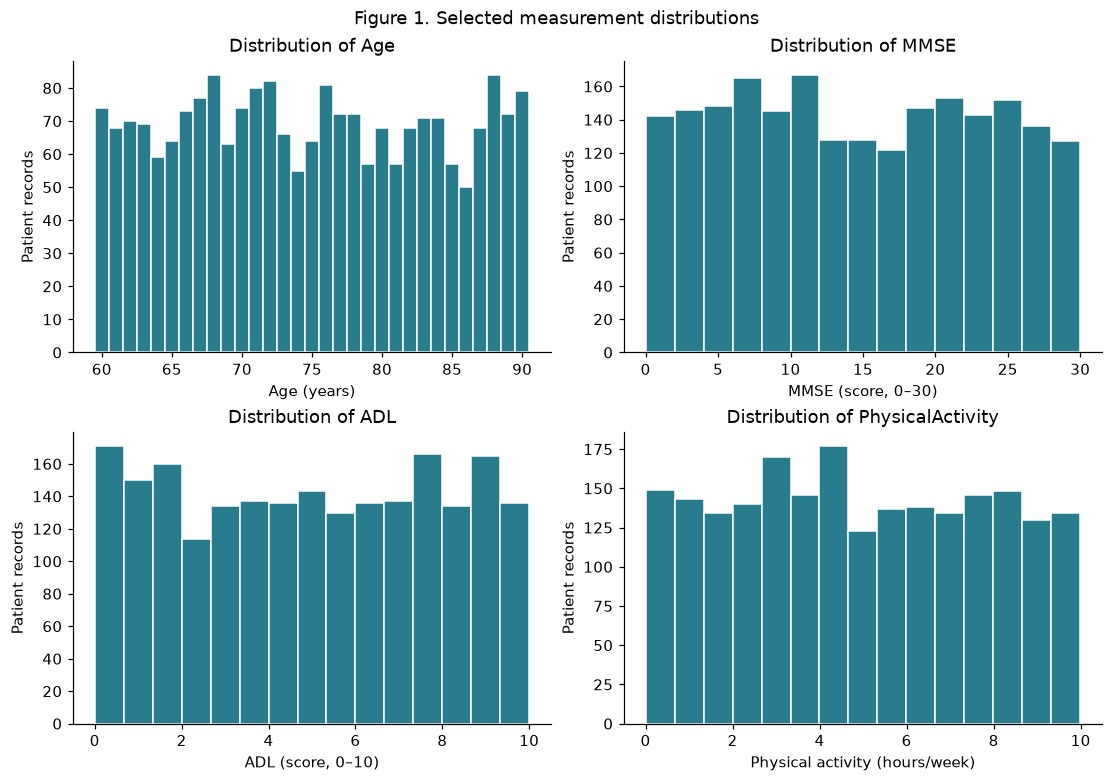

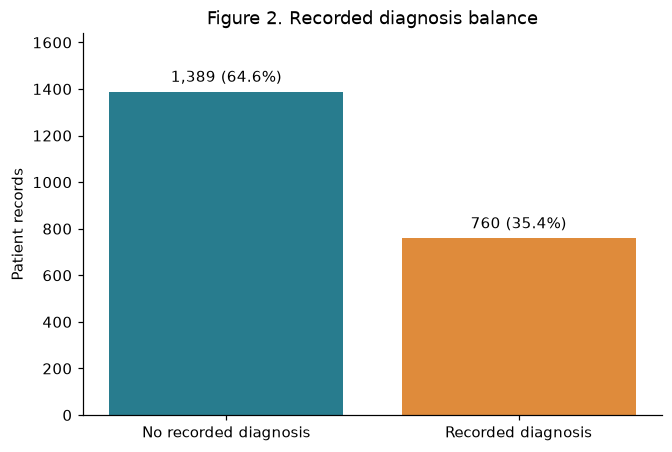

Diagnosis is recorded for 760/2,149 patients (35.37%). This is a sample proportion, not population prevalence.


In [6]:
fig,axes=plt.subplots(2,2,figsize=(10,7),layout='constrained')
for ax,c,label in zip(axes.flat,['Age','MMSE','ADL','PhysicalActivity'],
                      ['Age (years)','MMSE (score, 0–30)','ADL (score, 0–10)','Physical activity (hours/week)']):
    bins = np.arange(59.5,91.5,1) if c == 'Age' else 15
    ax.hist(df[c],bins=bins,color='#287c8e',edgecolor='white')
    ax.set(title=f'Distribution of {c}',xlabel=label,ylabel='Patient records')
fig.suptitle('Figure 1. Selected measurement distributions')
plt.show()
counts=df.Diagnosis.value_counts().reindex([0,1],fill_value=0)
fig,ax=plt.subplots(figsize=(6,4),layout='constrained')
bars=ax.bar(['No recorded diagnosis','Recorded diagnosis'],counts,color=['#287c8e','#df8b3b'])
ax.bar_label(bars,labels=[f'{n:,} ({n/len(df):.1%})' for n in counts],padding=4)
ax.set(title='Figure 2. Recorded diagnosis balance',ylabel='Patient records',ylim=(0,counts.max()*1.18))
plt.show()
print(f'Diagnosis is recorded for {counts[1]:,}/{len(df):,} patients ({counts[1]/len(df):.2%}). This is a sample proportion, not population prevalence.')


## 6. Three research questions, plans and preliminary answers

### Question 1 — How do MMSE scores differ between records with and without an Alzheimer's diagnosis?

**Rationale:** This examines whether recorded diagnosis and cognitive assessment are aligned within this table.

**Variables:** Comparison outcome = MMSE; grouping variable = Diagnosis. Age is a potential confounder for later work.

**Plan:** Retain records with valid diagnosis and MMSE values; report group sizes, mean, SD, median and quartiles; compare the mean difference (diagnosis yes minus no) and a descriptive standardized difference. Inspect distribution overlap in a boxplot. This is an association analysis, not a diagnostic accuracy study.

**Visualization:** MMSE boxplots by diagnosis, with the complete 0–30 scale.

**Limitations:** Diagnostic criteria and assessment timing are unknown. MMSE may have contributed to assigning diagnosis, so the relationship may be partly circular. Fractional scores and unknown provenance limit clinical interpretation. Groups can differ in age, education and other characteristics.


,n,mean,sd,median,q1,q3
Diagnosis,,,,,,
No,1389,16.266,8.933,17.146,8.545,24.596
Yes,760,11.995,7.226,11.566,6.040,18.152


**Answer:** The diagnosis-yes minus diagnosis-no mean MMSE difference is **-4.27 points** (descriptive standardized difference **-0.51**). The boxplots show whether the groups overlap; this difference cannot establish an independent diagnostic test or a causal effect.

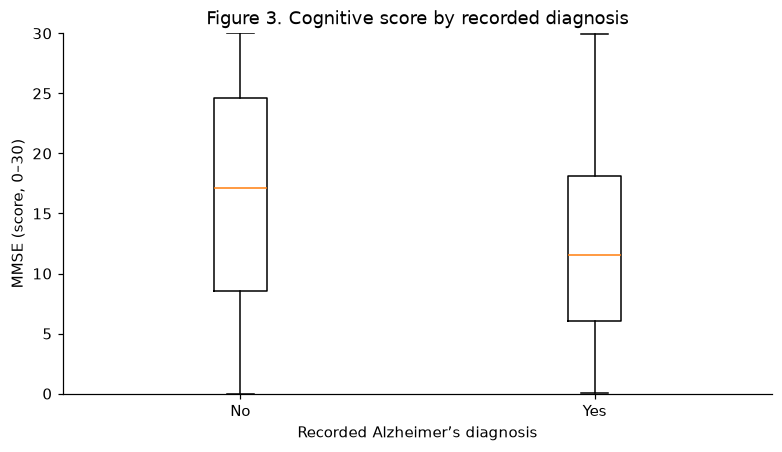

In [7]:
def summary_by(data, group, value):
    return data.groupby(group,observed=True)[value].agg(
        n='count',mean='mean',sd='std',median='median',
        q1=lambda x:x.quantile(.25),q3=lambda x:x.quantile(.75))
q1=df.loc[df.Diagnosis.isin([0,1]) & df.MMSE.between(0,30)].copy()
s1=summary_by(q1,'Diagnosis','MMSE')
display(s1.rename(index={0:'No',1:'Yes'}))
mean_difference=s1.loc[1,'mean']-s1.loc[0,'mean']
pooled_sd=np.sqrt(((s1['n']-1)*s1['sd']**2).sum()/(s1['n'].sum()-2))
display(Markdown(f'**Answer:** The diagnosis-yes minus diagnosis-no mean MMSE difference is **{mean_difference:.2f} points** (descriptive standardized difference **{mean_difference/pooled_sd:.2f}**). The boxplots show whether the groups overlap; this difference cannot establish an independent diagnostic test or a causal effect.'))
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
ax.boxplot([q1.loc[q1.Diagnosis.eq(g),'MMSE'] for g in [0,1]])
ax.set(xticks=[1,2],xticklabels=['No','Yes'],xlabel='Recorded Alzheimer’s diagnosis',ylabel='MMSE (score, 0–30)',ylim=(0,30),title='Figure 3. Cognitive score by recorded diagnosis')
plt.show()


### Question 2 — Is weekly physical activity associated with daily functioning (ADL), overall and within diagnosis groups?

**Rationale:** This explores the relationship between a lifestyle measurement and a functional assessment without assuming diagnosis must be the outcome.

**Variables:** Comparison outcome = ADL; explanatory measurement = PhysicalActivity; descriptive stratification = Diagnosis.

**Plan:** Use valid activity and ADL ranges. Report Spearman rank correlation overall and separately by diagnosis. Compare ADL summaries across four fixed activity intervals (0–2.5, >2.5–5, >5–7.5, >7.5–10 hours/week). These intervals simplify description; correlation uses the original unbinned values.

**Visualization:** Scatterplots by diagnosis; transparent points reveal density and overlap.

**Limitations:** Activity may depend on functional ability, so reverse causation is possible. Age, mobility, measurement timing and other factors may confound the association. Stratifying on diagnosis describes subgroups and does not create causal adjustment; it can itself introduce selection bias. A near-zero rank correlation would not exclude all nonlinear relationships.


,Group,n,Spearman rho
0,All,2149,-0.014
1,Diagnosis=0,1389,-0.039
2,Diagnosis=1,760,0.039


,n,mean,sd,median,q1,q3
ActivityBand,,,,,,
0–2.5,523,5.206,2.919,5.302,2.758,7.784
>2.5–5,582,4.857,2.999,4.860,2.023,7.617
>5–7.5,524,4.681,2.911,4.677,2.094,7.174
>7.5–10,520,5.204,2.937,5.474,2.578,7.675


**Answer:** Overall Spearman rho is **-0.014**. The subgroup coefficients and activity-band summaries above show the direction and size of the observed pattern. This does not estimate the effect of increasing exercise.

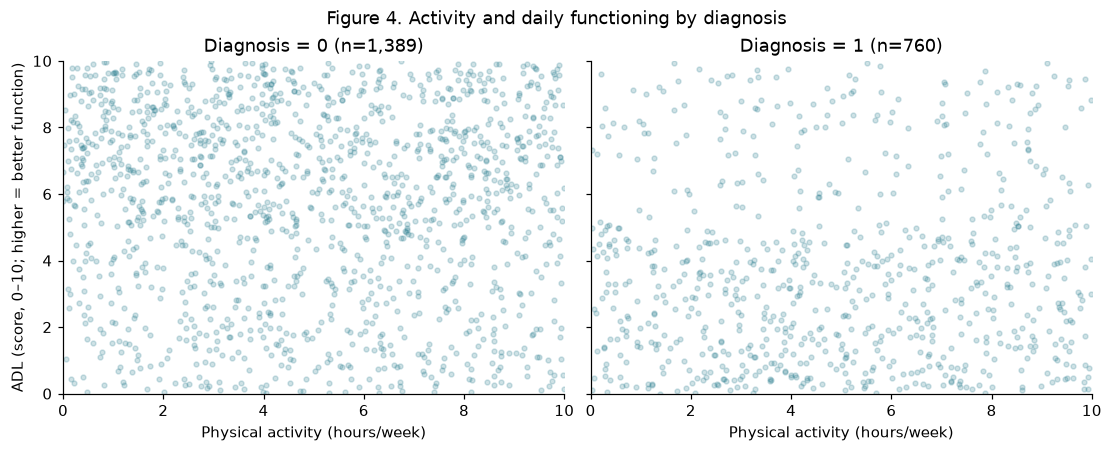

In [8]:
q2=df.loc[df.PhysicalActivity.between(0,10) & df.ADL.between(0,10)].copy()
def rank_corr(data,x,y):
    return data[x].rank().corr(data[y].rank())
r2=rank_corr(q2,'PhysicalActivity','ADL')
correlations=[['All',len(q2),r2]]
for g in [0,1]:
    d=q2.loc[q2.Diagnosis.eq(g)]
    correlations.append([f'Diagnosis={g}',len(d),rank_corr(d,'PhysicalActivity','ADL')])
display(pd.DataFrame(correlations,columns=['Group','n','Spearman rho']))
q2['ActivityBand']=pd.cut(q2.PhysicalActivity,[0,2.5,5,7.5,10],include_lowest=True,
                         labels=['0–2.5','>2.5–5','>5–7.5','>7.5–10'])
display(summary_by(q2,'ActivityBand','ADL'))
display(Markdown(f'**Answer:** Overall Spearman rho is **{r2:.3f}**. The subgroup coefficients and activity-band summaries above show the direction and size of the observed pattern. This does not estimate the effect of increasing exercise.'))
fig,axes=plt.subplots(1,2,figsize=(10,4),sharex=True,sharey=True,layout='constrained')
for ax,g in zip(axes,[0,1]):
    d=q2.loc[q2.Diagnosis.eq(g)]
    ax.scatter(d.PhysicalActivity,d.ADL,s=10,alpha=.22,color='#287c8e')
    ax.set(title=f'Diagnosis = {g} (n={len(d):,})',xlabel='Physical activity (hours/week)',xlim=(0,10),ylim=(0,10))
axes[0].set_ylabel('ADL (score, 0–10; higher = better function)')
fig.suptitle('Figure 4. Activity and daily functioning by diagnosis')
plt.show()


### Question 3 — How do MMSE distributions vary by education level, and does the pattern persist within age bands?

**Rationale:** This assesses whether cognitive-score comparisons depend on demographic grouping, and whether an overall education pattern changes after simple age stratification.

**Variables:** Outcome = MMSE; group = EducationLevel (four ordered categories); stratification = Age in years, grouped as 60–69, 70–79, 80–90.

**Plan:** Report group sizes and MMSE summaries by education, then education-by-age summaries and a cross-tabulation of cell sizes. Compare the highest-versus-lowest education mean difference overall and within each age band. Do not treat education codes as equally spaced years of schooling.

**Visualization:** Four education boxplots within each age band, with consistent score scales.

**Limitations:** Broad age bands leave residual age differences. Language, assessment adaptation, literacy, socioeconomic circumstances and sampling are unknown. Small subgroups have less stable summaries. Differences cannot establish that education prevents disease or raises cognitive scores. The oldest band covers 11 integer ages rather than 10.


,n,mean,sd,median,q1,q3
EducationLevel,,,,,,
None,446,14.177,8.587,12.740,6.560,21.747
High School,854,14.833,8.777,14.806,6.998,22.651
Bachelor's,636,15.075,8.438,14.870,7.775,22.307
Higher,213,14.697,8.521,14.570,7.267,21.708


EducationLevel,None,High School,Bachelor's,Higher
AgeBand,,,,
60–69,127,271,227,76
70–79,151,274,213,65
80–90,168,309,196,72


n    mean     sd  median     q1      q3
AgeBand EducationLevel                                           
60–69   0               127  14.663  8.377  13.987  6.919  21.798
        1               271  14.794  9.183  14.421  6.756  23.110
        2               227  15.072  8.579  15.964  7.683  22.306
        3                76  15.029  8.152  14.794  7.565  21.869
70–79   0               151  13.872  8.502  11.522  6.510  21.319
        1               274  14.698  8.463  14.540  7.071  22.482
        2               213  14.875  8.206  14.304  8.013  21.746
        3                65  15.673  8.697  15.229  8.702  22.637
80–90   0               168  14.084  8.852  12.632  6.391  21.684
        1               309  14.988  8.714  15.245  7.305  22.170
        2               196  15.296  8.558  14.830  7.703  22.895
        3                72  13.465  8.710  12.245  6.151  20.521

,Higher minus None: MMSE points
AgeBand,
60–69,0.367
70–79,1.802
80–90,-0.619


**Answer:** The overall mean MMSE difference between Higher and None is **0.52 points**. The age-band differences above assess whether this descriptive contrast is consistent across ages; the boxplots expose within-group variation.

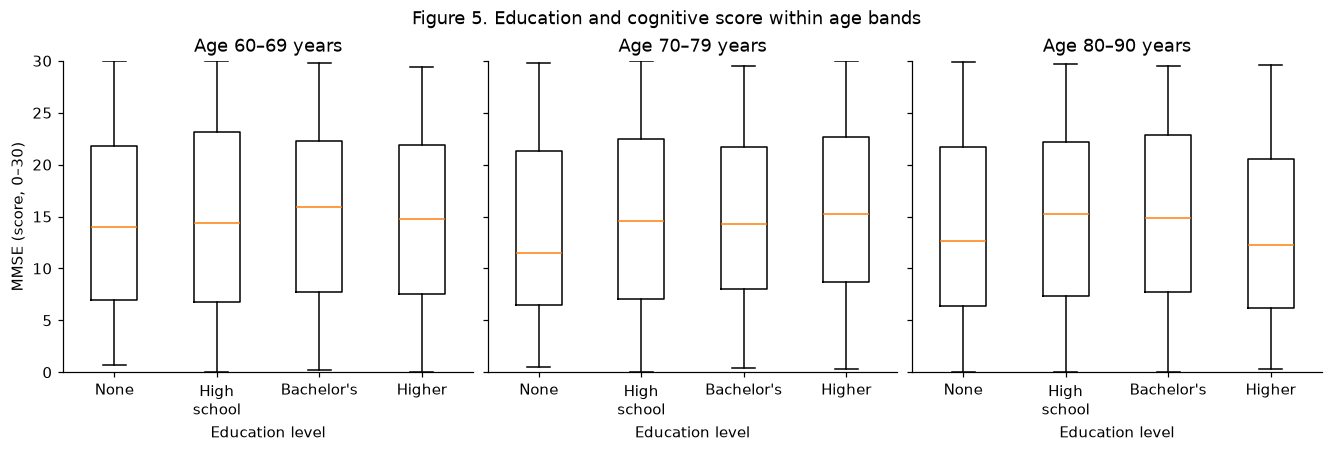

In [9]:
q3=df.loc[df.EducationLevel.isin([0,1,2,3]) & df.Age.between(60,90) & df.MMSE.between(0,30)].copy()
q3['AgeBand']=pd.cut(q3.Age,[59,69,79,90],labels=['60–69','70–79','80–90'])
s3=summary_by(q3,'EducationLevel','MMSE')
display(s3.rename(index=category_maps['EducationLevel']))
display(pd.crosstab(q3.AgeBand,q3.EducationLevel).rename(columns=category_maps['EducationLevel']))
display(summary_by(q3,['AgeBand','EducationLevel'],'MMSE'))
means=q3.groupby(['AgeBand','EducationLevel'],observed=True).MMSE.mean().unstack()
contrasts=(means[3]-means[0]).rename('Higher minus None: MMSE points')
display(contrasts.to_frame())
display(Markdown(f'**Answer:** The overall mean MMSE difference between Higher and None is **{s3.loc[3,"mean"]-s3.loc[0,"mean"]:.2f} points**. The age-band differences above assess whether this descriptive contrast is consistent across ages; the boxplots expose within-group variation.'))
fig,axes=plt.subplots(1,3,figsize=(12,4),sharey=True,layout='constrained')
for ax,band in zip(axes,q3.AgeBand.cat.categories):
    d=q3.loc[q3.AgeBand.eq(band)]
    ax.boxplot([d.loc[d.EducationLevel.eq(e),'MMSE'] for e in range(4)])
    ax.set(xticks=[1,2,3,4],xticklabels=['None','High\nschool',"Bachelor's",'Higher'],title=f'Age {band} years',xlabel='Education level',ylim=(0,30))
axes[0].set_ylabel('MMSE (score, 0–30)')
fig.suptitle('Figure 5. Education and cognitive score within age bands')
plt.show()


## 7. Additional audit: identifier order

The identifier must not be interpreted as a biological exposure or included in a clinical prediction model. Checking its ordering can reveal collection or construction artifacts. Compare diagnosis proportions across consecutive identifier quartiles; large differences would motivate questions about how records were assembled. This is a quality check, not a fourth research question.


In [10]:
order_check=df.assign(IDBlock=pd.qcut(df.PatientID,4,labels=['First quarter','Second quarter','Third quarter','Last quarter']))
display(order_check.groupby('IDBlock',observed=True).Diagnosis.agg(n='size',diagnosis_proportion='mean'))


,n,diagnosis_proportion
IDBlock,,
First quarter,538,0.342
Second quarter,537,0.337
Third quarter,537,0.348
Last quarter,537,0.387


## 8. Data-quality note and appropriate next steps

**Answers from the supplied CSV:** the diagnosed group has a mean MMSE of 11.99 versus 16.27 in the other group, a difference of −4.27 points, with substantial distribution overlap. Activity and ADL show almost no monotonic association (Spearman rho −0.014 overall, −0.039 without diagnosis and +0.039 with diagnosis). ADL means across activity bands are 5.21, 4.86, 4.68 and 5.20, so there is no steadily increasing pattern; the mild U-shaped pattern is descriptive and would need independent investigation. Education-group mean MMSE scores are 14.18, 14.83, 15.08 and 14.70: they do not increase monotonically. The Higher-minus-None contrast is +0.37, +1.80 and −0.62 points across the three age bands, so its direction is not consistent across ages. These are preliminary answers to the three proposed questions, not confirmatory hypothesis tests.

The audit explicitly reports missingness, duplicate rows and IDs, constant fields, category validity, ranges, decimal precision and cross-field inconsistencies. The supplied file has no missing values or exact duplicate rows. `DoctorInCharge` is constant and uninformative. IDs run from 4751 to 6899; the dictionary's inclusive upper bound of 6900 is not present. That discrepancy does not prove a patient record was lost.

All declared category codes and single-variable ranges pass. Nevertheless, 186 records (8.66%) have systolic blood pressure less than or equal to diastolic blood pressure, and 114 (5.30%) have LDL cholesterol above total cholesterol. All 2,149 MMSE values are fractional. Some scores have many decimal places, and several measurements have broad, nearly even distributions. These are reasons to verify provenance and measurement procedures; they do not by themselves prove that the dataset is synthetic. Cross-field flags need source checking even when each value separately passes its stated range. No records are removed for these flags in the three analyses, which do not use the flagged blood-pressure or cholesterol values.

The diagnosis groups are 64.63% no and 35.37% yes, so they are unequal but both sizeable. The smallest education group is Higher (213 records); the smallest education-by-age cell has 65 records. Diagnosis proportions across identifier quartiles range from 33.71% to 38.73%; this modest variation is recorded as an ordering check and does not justify using ID as a substantive predictor.

Keep the original file unchanged. Obtain the data source, sampling method, diagnosis criteria, measurement dates, instrument definitions and score precision before clinical interpretation. Confirm whether the data are real, simulated or transformed. No follow-up dates, incident diagnoses, treatment information or longitudinal outcomes are available: disease progression, time to onset and treatment effects cannot be answered here. Descriptive differences are not evidence of causation. No clinical thresholds, population prevalence claims, p-value screening or predictive-performance claims are needed for Part A.

The three questions replace repetitive “does each risk factor predict diagnosis?” questions with complementary comparisons. Their tables and figures provide preliminary answers; any further inferential analysis should be prespecified after provenance and study design are clarified.


## 9. Optional file and submission checklist

The optional `data.h5` was inspected structurally using h5py. It contains a pandas-style group `/df` with three rows (indices 0, 1, 2) and three columns: `Name`, `Age`, and `Score`. It has no `PatientID` or documented link to the Alzheimer's CSV. It is therefore not used or merged. Its object-valued block was not deserialized; the schema alone is sufficient to establish that it is not the supplied 2,149-row patient table. The CSV and dictionary are sufficient for all Part A requirements.

| Assignment deliverable | Included |
|---|---|
| Planned examinations | Section 1, before code |
| Data audit and selected EDA | Sections 2, 4, 5 and 7 |
| Short dictionary with types and uncertainties | Section 3 |
| Three questions, rationale, variables, plan, visualization, limitations | Section 6 |
| At least two informative, labeled exploratory figures | Figures 1–5 |
| Short data-quality note | Section 8 |

**Submission:** review all results and your course's AI disclosure requirements; add the group members if required. This notebook is prepared for [the requested GitHub repository](https://github.com/gebreabgithub/python_Task_3A). [Open it in Colab](https://colab.research.google.com/github/gebreabgithub/python_Task_3A/blob/main/Assignment_3A_Alzheimers_Explore_and_Plan.ipynb). The supplied Google Sheet is a register; adding a submission row requires knowing the correct group and is separate from preparing this notebook.
